In [1]:
import os
import json
import torch
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms

In [2]:
image_paths = [
    os.path.join("data/cleaned", f)
    for f in os.listdir("data/cleaned")
]

print("Number of images:", len(image_paths))

FileNotFoundError: [WinError 3] The system cannot find the path specified: 'data/cleaned'

In [1]:
import os
print(os.getcwd())

C:\Users\Acer\Downloads\04_AutoPilot_AI\notebooks


In [2]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\Acer\Downloads\04_AutoPilot_AI\notebooks
['.ipynb_checkpoints', '01_data_exploration.ipynb', '02_eda.ipynb', 'untitled.py']


In [3]:
image_dir = "../data/cleaned"

import os
print(os.path.exists(image_dir))
print(len(os.listdir(image_dir)))

True
27


In [4]:
image_paths = [
    os.path.join(image_dir, f)
    for f in os.listdir(image_dir)
]

print("Number of images:", len(image_paths))

Number of images: 27


In [5]:
labels = [0] * len(image_paths)

print("Number of labels:", len(labels))

Number of labels: 27


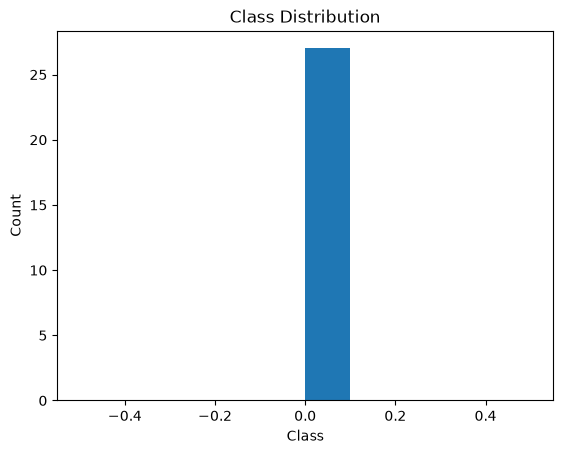

In [6]:
import matplotlib.pyplot as plt

plt.hist(labels)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

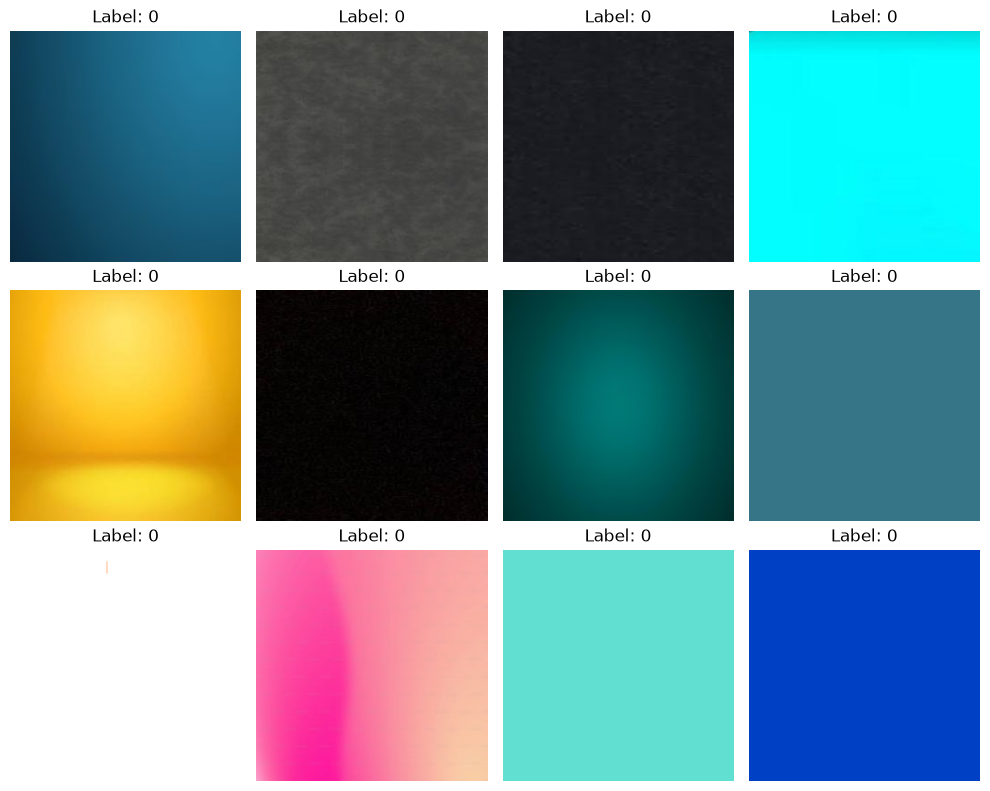

In [7]:
from PIL import Image
import matplotlib.pyplot as plt
import random

sample_images = random.sample(image_paths, min(12, len(image_paths)))

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax, img_path in zip(axes.flatten(), sample_images):
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title("Label: 0")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import torch
from PIL import Image
from torchvision import transforms

transform = transforms.ToTensor()

images = []

for img_path in image_paths:
    img = Image.open(img_path).convert("RGB")
    img = transform(img)
    images.append(img)

stacked = torch.stack(images)

mean = stacked.mean(dim=(0, 2, 3))
std = stacked.std(dim=(0, 2, 3))

print("Mean:", mean)
print("Std:", std)

Mean: tensor([0.3580, 0.5609, 0.5699])
Std: tensor([0.3439, 0.3407, 0.3389])


In [9]:
import json

stats = {
    "mean": mean.tolist(),
    "std": std.tolist()
}

with open("../data/mean_std.json", "w") as f:
    json.dump(stats, f, indent=4)

print("Saved to data/mean_std.json")

Saved to data/mean_std.json


In [10]:
with open("../data/mean_std.json", "r") as f:
    print(f.read())

{
    "mean": [
        0.3579845130443573,
        0.5608879923820496,
        0.5698756575584412
    ],
    "std": [
        0.3438735902309418,
        0.3407387435436249,
        0.3389030694961548
    ]
}
